# Titanic: Machine Learning from Disaster
Goal: predict which passengers survived the Titanic.

Steps: loading the data, exploring it, feature engineering, modeling and evaluation

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')
sns.set()

## Loading the data

In [2]:
# the csv files must be in the same folder as this notebook
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(train.shape)
print(test.shape)
train.head()

(891, 12)
(418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Exploratory Data Analysis

In [3]:
train.info()
print()
print('Missing values in train:')
print(train.isnull().sum())
print()
print('Missing values in test:')
print(test.isnull().sum())
print()
print('Duplicated rows:', train.duplicated().sum(), test.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values in train:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype

In [4]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


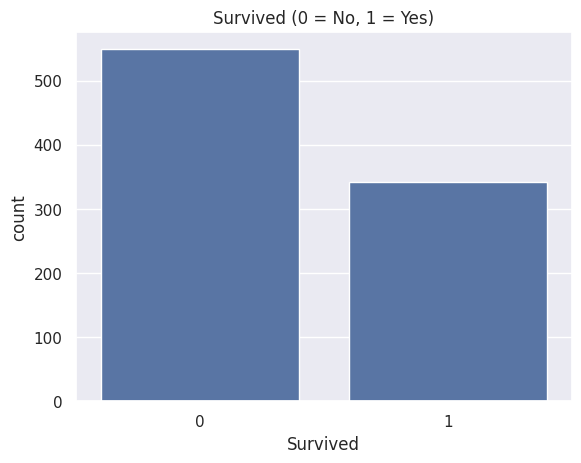

In [5]:
# how many survived
sns.countplot(x='Survived', data=train)
plt.title('Survived (0 = No, 1 = Yes)')
plt.show()

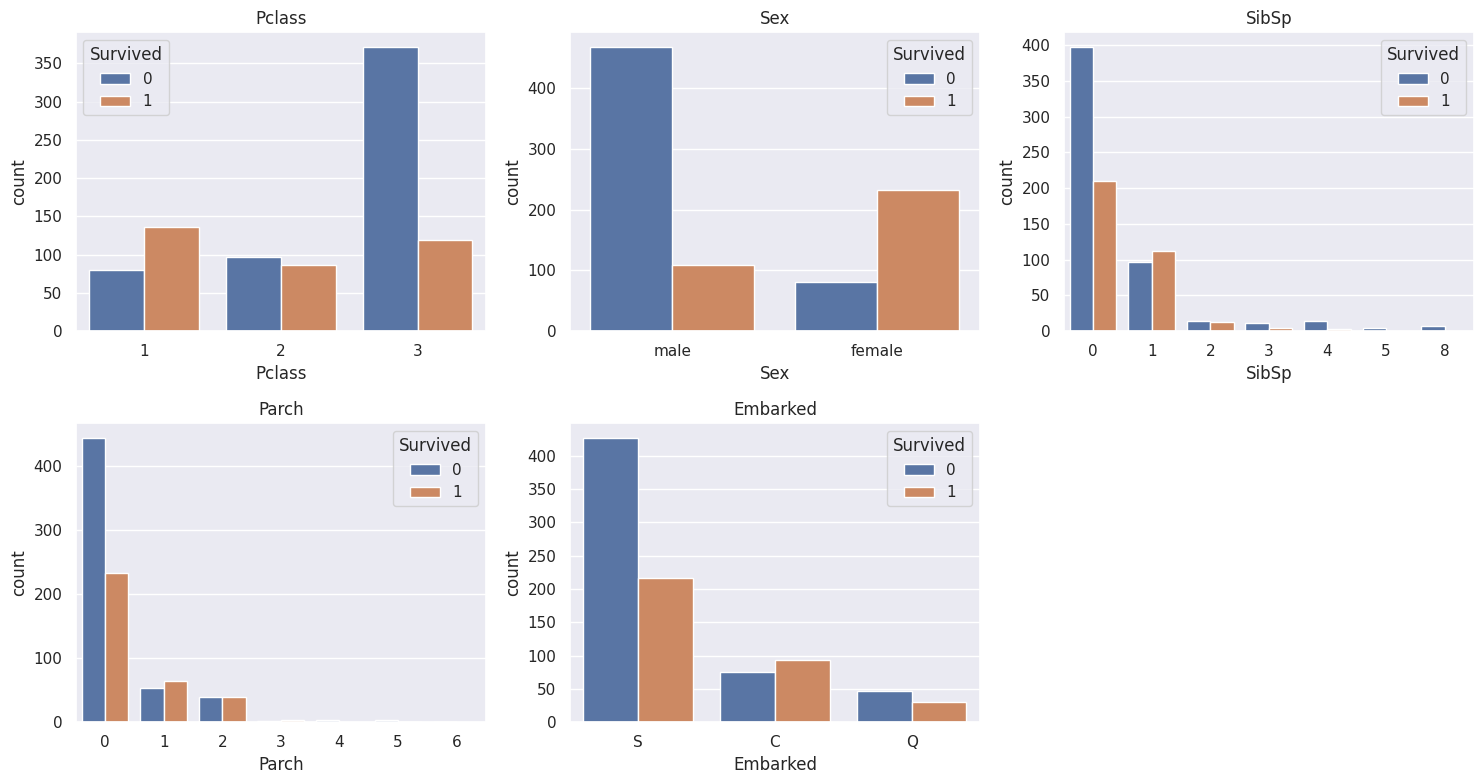

In [6]:
# survival for each categorical feature
features = ['Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked']

plt.figure(figsize=(15, 8))
for i in range(len(features)):
    plt.subplot(2, 3, i + 1)
    sns.countplot(x=features[i], hue='Survived', data=train)
    plt.title(features[i])
plt.tight_layout()
plt.show()

## Feature Engineering

In [7]:
# Name -> Title
data = [train, test]

for df in data:
    df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\\.', expand=False)

print(train['Title'].value_counts())

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


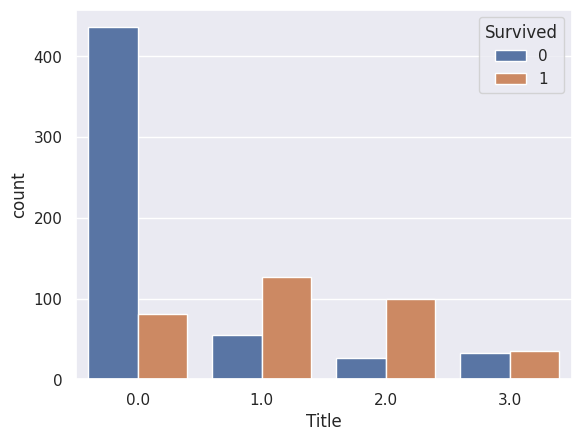

In [8]:
# Mr = 0, Miss = 1, Mrs = 2, all the rare titles = 3
title_mapping = {"Mr": 0, "Miss": 1, "Mrs": 2}

for df in data:
    df['Title'] = df['Title'].map(title_mapping)
    df['Title'] = df['Title'].fillna(3)

train = train.drop('Name', axis=1)
test = test.drop('Name', axis=1)
data = [train, test]

sns.countplot(x='Title', hue='Survived', data=train)
plt.show()

In [9]:
# Sex: male = 1, female = 0
for df in data:
    df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})

train.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,0,3,1,22.0,1,0,A/5 21171,7.2500,NaN,S,0.0
1,2,1,1,0,38.0,1,0,PC 17599,71.2833,C85,C,2.0
2,3,1,3,0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1.0
3,4,1,1,0,35.0,1,0,113803,53.1000,C123,S,2.0
4,5,0,3,1,35.0,0,0,373450,8.0500,NaN,S,0.0


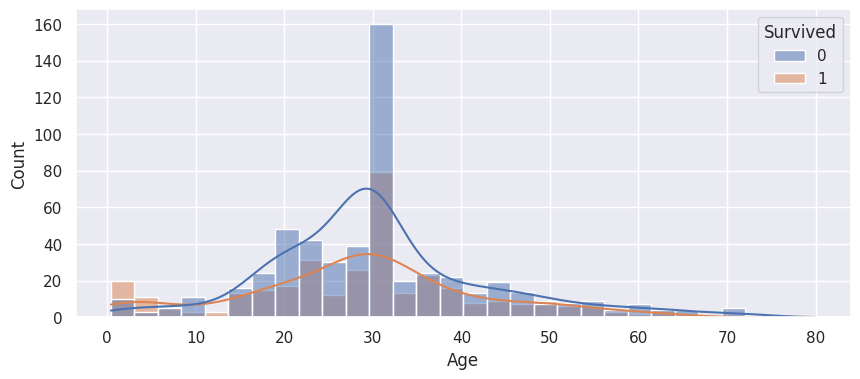

In [10]:
# Age: fill the missing values with the mean age
mean_age = train['Age'].mean()
train['Age'] = train['Age'].fillna(mean_age)
test['Age'] = test['Age'].fillna(mean_age)

plt.figure(figsize=(10, 4))
sns.histplot(data=train, x='Age', hue='Survived', kde=True)
plt.show()

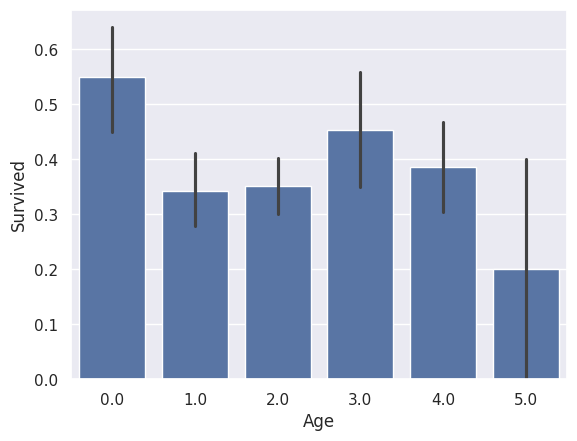

In [11]:
# Age groups
for df in data:
    df.loc[df['Age'] <= 16, 'Age'] = 0
    df.loc[(df['Age'] > 16) & (df['Age'] <= 26), 'Age'] = 1
    df.loc[(df['Age'] > 26) & (df['Age'] <= 34), 'Age'] = 2
    df.loc[(df['Age'] > 34) & (df['Age'] <= 40), 'Age'] = 3
    df.loc[(df['Age'] > 40) & (df['Age'] <= 62), 'Age'] = 4
    df.loc[df['Age'] > 62, 'Age'] = 5

sns.barplot(x='Age', y='Survived', data=train)
plt.show()

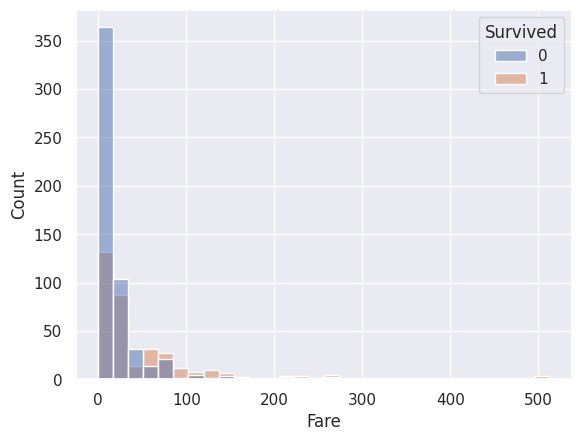

In [12]:
# Embarked: fill with S (the most common) and convert to numbers
for df in data:
    df['Embarked'] = df['Embarked'].fillna('S')
    df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# Fare: the one missing value in test is filled with the median fare of its class
test['Fare'] = test['Fare'].fillna(test.groupby('Pclass')['Fare'].transform('median'))

sns.histplot(data=train, x='Fare', hue='Survived', bins=30)
plt.show()

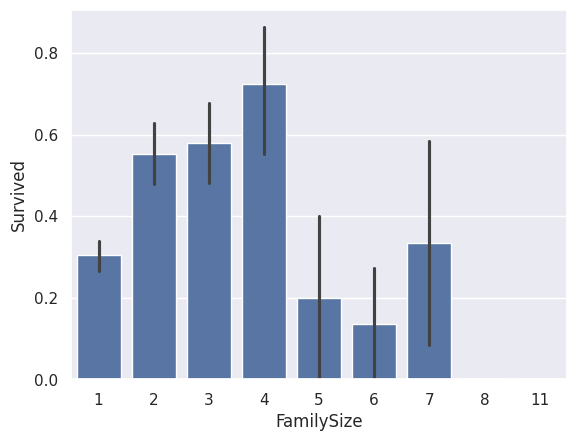

In [13]:
# Fare groups
for df in data:
    df.loc[df['Fare'] <= 17, 'Fare'] = 0
    df.loc[(df['Fare'] > 17) & (df['Fare'] <= 30), 'Fare'] = 1
    df.loc[(df['Fare'] > 30) & (df['Fare'] <= 100), 'Fare'] = 2
    df.loc[df['Fare'] > 100, 'Fare'] = 3

# Cabin has too many missing values so it is dropped
train = train.drop('Cabin', axis=1)
test = test.drop('Cabin', axis=1)
data = [train, test]

# Family size
for df in data:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

sns.barplot(x='FamilySize', y='Survived', data=train)
plt.show()

In [14]:
# drop the columns we do not need
train = train.drop(['Ticket', 'SibSp', 'Parch', 'PassengerId'], axis=1)
test = test.drop(['Ticket', 'SibSp', 'Parch'], axis=1)

print(train.isnull().sum())
train.head()

Survived      0
Pclass        0
Sex           0
Age           0
Fare          0
Embarked      0
Title         0
FamilySize    0
dtype: int64


,Survived,Pclass,Sex,Age,Fare,Embarked,Title,FamilySize
0,0,3,1,1.0,0.0,0,0.0,2
1,1,1,0,3.0,2.0,1,2.0,2
2,1,3,0,1.0,0.0,0,1.0,1
3,1,1,0,3.0,2.0,0,2.0,2
4,0,3,1,3.0,0.0,0,0.0,1


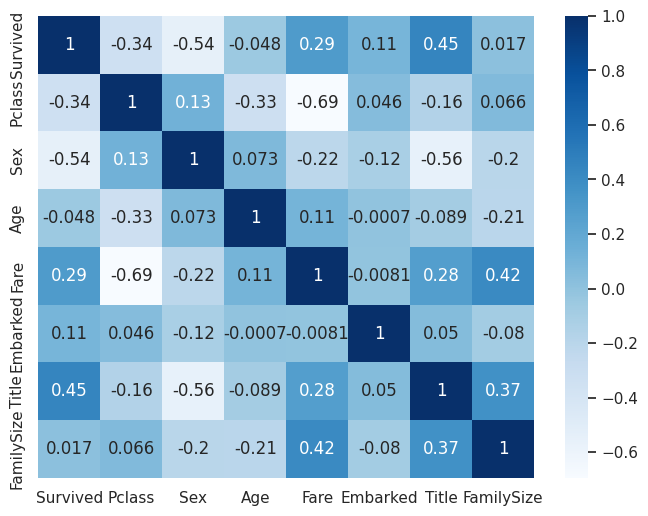

Survived      1.000000
Pclass       -0.338481
Sex          -0.543351
Age          -0.048389
Fare          0.292884
Embarked      0.106811
Title         0.445792
FamilySize    0.016639
Name: Survived, dtype: float64


In [15]:
# correlation
plt.figure(figsize=(8, 6))
sns.heatmap(train.corr(), annot=True, cmap='Blues')
plt.show()

print(train.corr()['Survived'])

## Modeling

In [16]:
train_data = train.drop('Survived', axis=1)
target = train['Survived']

print(train_data.shape, target.shape)

(891, 7) (891,)


### Cross validation

In [17]:
k_fold = KFold(n_splits=5, shuffle=True, random_state=42)

models = [
    ('KNN', KNeighborsClassifier(n_neighbors=9)),
    ('Decision Tree', DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=5, random_state=42)),
    ('Naive Bayes', GaussianNB()),
    ('Logistic Regression', LogisticRegression()),
    ('SVM', SVC(kernel='rbf', random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, learning_rate=0.01, max_depth=4, random_state=42)),
    ('AdaBoost', AdaBoostClassifier(n_estimators=100, learning_rate=0.01)),
    ('XGBoost', XGBClassifier(max_depth=4, learning_rate=0.01, n_estimators=100, random_state=42)),
]

# voting model (hard voting)
model1 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
model2 = XGBClassifier(max_depth=4, learning_rate=0.1, n_estimators=100, random_state=42)
model3 = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=5, random_state=42)
voting = VotingClassifier(estimators=[('dt', model1), ('xgb', model2), ('rf', model3)], voting='hard')
models.append(('Voting', voting))

names = []
cv_scores = []

for name, model in models:
    score = cross_val_score(model, train_data, target, cv=k_fold, scoring='accuracy')
    result = round(np.mean(score) * 100, 2)
    names.append(name)
    cv_scores.append(result)
    print(name, ':', result)

KNN : 81.59
Decision Tree : 83.17


Random Forest : 83.39
Naive Bayes : 80.03
Logistic Regression : 81.93
SVM : 82.6


Gradient Boosting : 82.72


AdaBoost : 78.56
XGBoost : 83.05


Voting : 83.17


                 Model  Score
2        Random Forest  83.39
1        Decision Tree  83.17
9               Voting  83.17
8              XGBoost  83.05
6    Gradient Boosting  82.72
5                  SVM  82.60
4  Logistic Regression  81.93
0                  KNN  81.59
3          Naive Bayes  80.03
7             AdaBoost  78.56


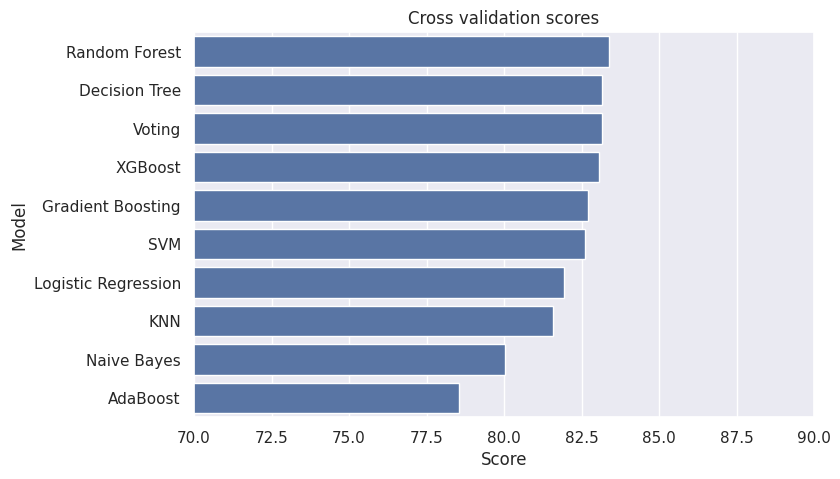

In [18]:
df_scores = pd.DataFrame({'Model': names, 'Score': cv_scores})
df_scores = df_scores.sort_values(by='Score', ascending=False)
print(df_scores)

plt.figure(figsize=(8, 5))
sns.barplot(x='Score', y='Model', data=df_scores)
plt.xlim(70, 90)
plt.title('Cross validation scores')
plt.show()

## Train Test Split

In [19]:
X = train.drop('Survived', axis=1)
y = train['Survived']

# 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape, X_test.shape)

(623, 7) (268, 7)


In [20]:
models2 = [
    ('Logistic Regression', LogisticRegression(random_state=42)),
    ('KNN', KNeighborsClassifier(n_neighbors=7)),
    ('Naive Bayes', GaussianNB()),
    ('SVM', SVC(kernel='rbf', random_state=42)),
    ('Decision Tree', DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=4, max_features=6, random_state=42)),
    ('XGBoost', XGBClassifier(max_depth=4, learning_rate=0.01, n_estimators=100, random_state=42)),
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=100, learning_rate=0.01, max_depth=4, max_features=6, random_state=42)),
    ('AdaBoost', AdaBoostClassifier(n_estimators=100, learning_rate=0.1)),
]

# voting model with 4 models
m1 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
m2 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.01, max_depth=4, max_features=6, random_state=42)
m3 = XGBClassifier(max_depth=5, learning_rate=0.01, n_estimators=100, random_state=42)
m4 = RandomForestClassifier(n_estimators=100, criterion='entropy', max_depth=4, max_features=6, random_state=42)
v_clf = VotingClassifier(estimators=[('dt', m1), ('gb', m2), ('xgb', m3), ('rf', m4)], voting='hard')
models2.append(('Voting', v_clf))

test_names = []
train_acc = []
test_acc = []

for name, model in models2:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    test_names.append(name)
    train_acc.append(model.score(X_train, y_train) * 100)
    test_acc.append(accuracy_score(y_test, y_pred) * 100)

    print(name)
    print(confusion_matrix(y_test, y_pred))
    print('Train accuracy:', round(train_acc[-1], 2))
    print('Test accuracy:', round(test_acc[-1], 2))
    print(classification_report(y_test, y_pred))
    print('-' * 50)

Logistic Regression
[[134  23]
 [ 27  84]]
Train accuracy: 81.54
Test accuracy: 81.34
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       157
           1       0.79      0.76      0.77       111

    accuracy                           0.81       268
   macro avg       0.81      0.81      0.81       268
weighted avg       0.81      0.81      0.81       268

--------------------------------------------------


KNN


[[137  20]
 [ 32  79]]
Train accuracy: 84.91
Test accuracy: 80.6
              precision    recall  f1-score   support

           0       0.81      0.87      0.84       157
           1       0.80      0.71      0.75       111

    accuracy                           0.81       268
   macro avg       0.80      0.79      0.80       268
weighted avg       0.81      0.81      0.80       268

--------------------------------------------------
Naive Bayes
[[123  34]
 [ 23  88]]
Train accuracy: 81.86
Test accuracy: 78.73
              precision    recall  f1-score   support

           0       0.84      0.78      0.81       157
           1       0.72      0.79      0.76       111

    accuracy                           0.79       268
   macro avg       0.78      0.79      0.78       268
weighted avg       0.79      0.79      0.79       268

--------------------------------------------------
SVM
[[139  18]
 [ 29  82]]
Train accuracy: 83.15
Test accuracy: 82.46
              precision    rec

Random Forest
[[144  13]
 [ 35  76]]
Train accuracy: 84.91
Test accuracy: 82.09
              precision    recall  f1-score   support

           0       0.80      0.92      0.86       157
           1       0.85      0.68      0.76       111

    accuracy                           0.82       268
   macro avg       0.83      0.80      0.81       268
weighted avg       0.82      0.82      0.82       268

--------------------------------------------------


XGBoost
[[141  16]
 [ 34  77]]
Train accuracy: 84.91
Test accuracy: 81.34
              precision    recall  f1-score   support

           0       0.81      0.90      0.85       157
           1       0.83      0.69      0.75       111

    accuracy                           0.81       268
   macro avg       0.82      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268

--------------------------------------------------
Gradient Boosting
[[146  11]
 [ 35  76]]
Train accuracy: 84.43
Test accuracy: 82.84
              precision    recall  f1-score   support

           0       0.81      0.93      0.86       157
           1       0.87      0.68      0.77       111

    accuracy                           0.83       268
   macro avg       0.84      0.81      0.82       268
weighted avg       0.83      0.83      0.82       268

--------------------------------------------------


AdaBoost
[[135  22]
 [ 28  83]]
Train accuracy: 81.22
Test accuracy: 81.34
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       157
           1       0.79      0.75      0.77       111

    accuracy                           0.81       268
   macro avg       0.81      0.80      0.81       268
weighted avg       0.81      0.81      0.81       268

--------------------------------------------------


Voting
[[145  12]
 [ 35  76]]
Train accuracy: 84.59
Test accuracy: 82.46
              precision    recall  f1-score   support

           0       0.81      0.92      0.86       157
           1       0.86      0.68      0.76       111

    accuracy                           0.82       268
   macro avg       0.83      0.80      0.81       268
weighted avg       0.83      0.82      0.82       268

--------------------------------------------------


                 Model      Train       Test
4        Decision Tree  83.627608  83.208955
7    Gradient Boosting  84.430177  82.835821
9               Voting  84.590690  82.462687
3                  SVM  83.146067  82.462687
5        Random Forest  84.911717  82.089552
0  Logistic Regression  81.540931  81.343284
8             AdaBoost  81.219904  81.343284
6              XGBoost  84.911717  81.343284
1                  KNN  84.911717  80.597015
2          Naive Bayes  81.861958  78.731343


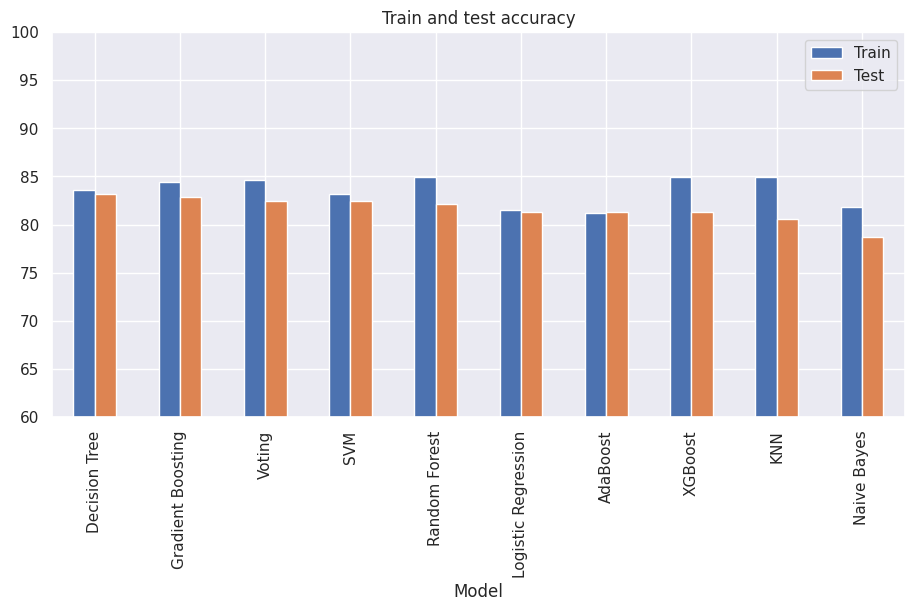

In [21]:
results = pd.DataFrame({'Model': test_names, 'Train': train_acc, 'Test': test_acc})
results = results.sort_values(by='Test', ascending=False)
print(results)

results.set_index('Model').plot(kind='bar', figsize=(11, 5))
plt.ylim(60, 100)
plt.title('Train and test accuracy')
plt.show()